# Chapter 10 — Loop closure and place recognition

Companion notebook to **Chapter 10**. The appearance simulation (binary descriptors with aliasing), a bag-of-binary-words
vocabulary learnt by k-majority, the tf-idf score, geometric verification, and the pose graph with the loops found
from the images (some of which are wrong).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import numpy as np
import matplotlib.pyplot as plt
from vslam import bow, features, lie, loop, optim, posegraph as pg, robust, sim
from ch10_loops import train_vocabulary, garden_keyframes, shared_matrix, rms, SIG_T, SIG_R

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. Simulated appearance: unique and repetitive landmarks

House, shed and trees have unique random 256-bit descriptors. Fence pickets and grass patches copy one of a few
prototypes with 4 % of the bits changed: perceptual aliasing. Each observation flips another 8 % of the bits (15 % on
grass).

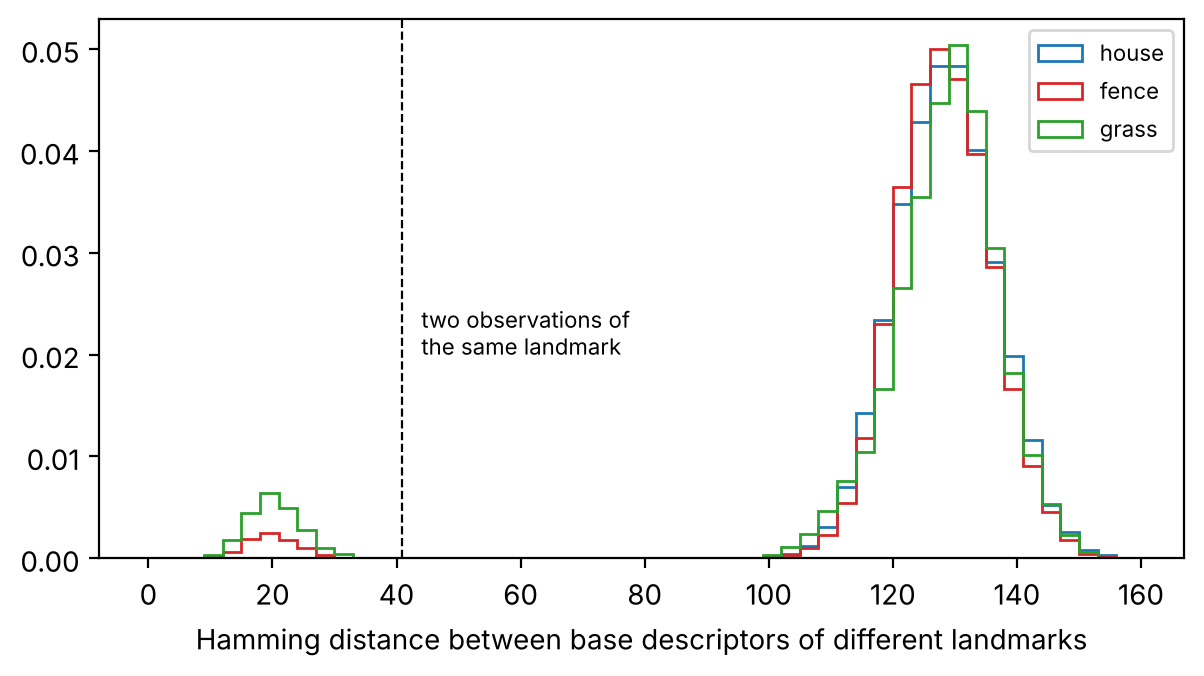

In [2]:
world = sim.garden(np.random.default_rng(0))
base = sim.landmark_descriptors(world, np.random.default_rng(1))
fig, ax = plt.subplots(figsize=(7, 3.5))
for kind, col in [("house", "tab:blue"), ("fence", "tab:red"), ("grass", "tab:green")]:
    idx = np.nonzero(world.kind == kind)[0][:300]
    D = features.hamming(base[idx], base[idx])[~np.eye(len(idx), dtype=bool)]
    ax.hist(D, bins=np.arange(0, 160, 3), histtype="step", density=True, color=col, label=kind)
ax.axvline(2 * 0.08 * 256, color="k", ls="--", lw=0.8)
ax.text(44, 0.02, "two observations of\nthe same landmark", fontsize=8)
ax.set_xlabel("Hamming distance between base descriptors of different landmarks"); ax.legend(fontsize=8)

Two different fence pickets are often closer than two observations of the same picket: no descriptor test can
tell them apart, and a match between them is a wrong correspondence that looks perfect.

## 2. k-majority: the cost never increases (Proposition 10.3)

monotone: True


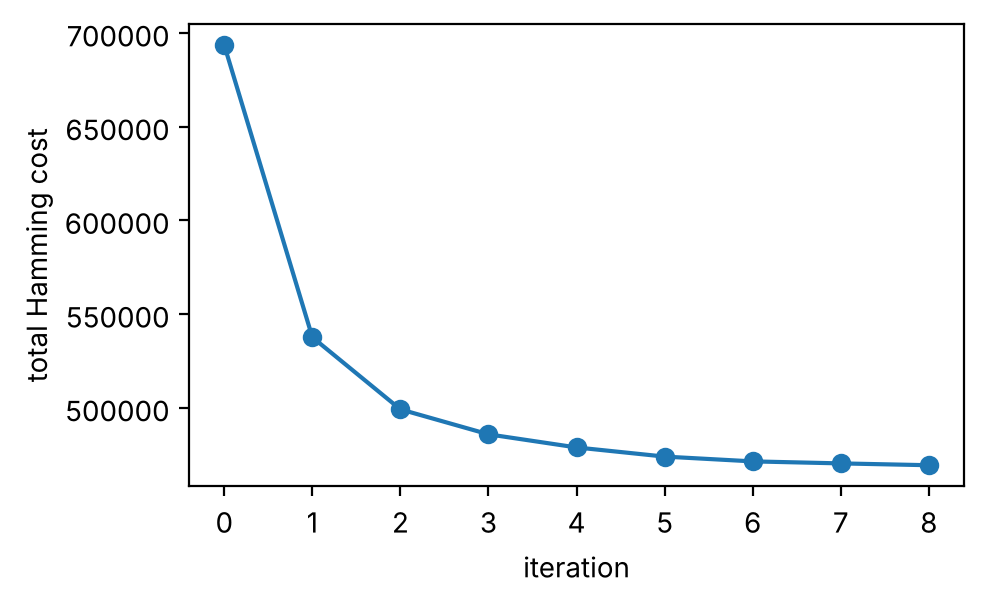

In [3]:
train = [sim.observe_descriptors(base, f, world, rng)
         for f in sim.GardenSim().run(world, sim.boustrophedon(), sim.camera_mount(), np.random.default_rng(3))[::40]]
_, costs = bow.kmajority(np.vstack(train), 200, iters=8, rng=np.random.default_rng(0))
plt.figure(figsize=(5, 3)); plt.plot(costs, "o-"); plt.xlabel("iteration"); plt.ylabel("total Hamming cost")
print("monotone:", np.all(np.diff(costs) <= 0))

## 3. The vocabulary and the keyframes of the garden run

The vocabulary (500 words) and the idf are learnt on a *different* garden, as a real system learns them offline. The
test run is the Chapter 7 keyframe VO.

153 keyframes; VO RMS error 36.5 cm
idf: min 0.04, median 0.96, max 2.52


Text(0.5, 1.0, 'shared structure landmarks')

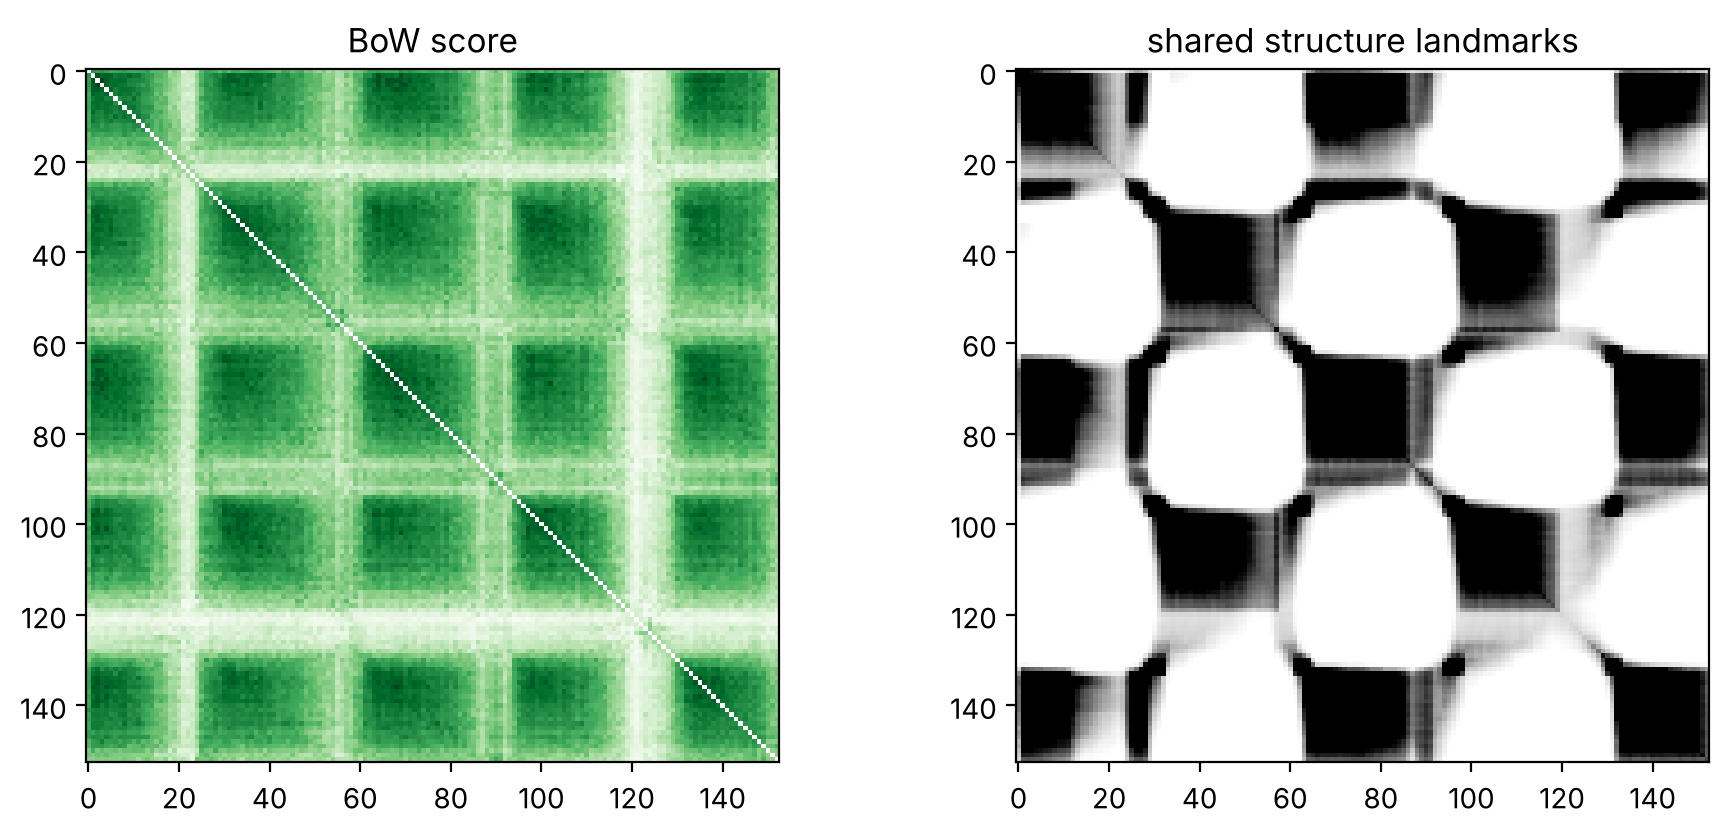

In [4]:
voc = train_vocabulary()
world, S, kfr, desc, P, G, sets = garden_keyframes()
shared = shared_matrix(sets)
print(f"{len(P)} keyframes; VO RMS error {100 * rms(P, G):.1f} cm")
print("idf: min %.2f, median %.2f, max %.2f" % (voc.idf.min(), np.median(voc.idf), voc.idf.max()))
det = loop.LoopDetector(voc, S.stereo, rng=np.random.default_rng(0))
for f, ds in zip(kfr, desc):
    det.add(f.z, ds)
V = np.array([k.bow for k in det.kfs])
Sm = bow.score_matrix(V); np.fill_diagonal(Sm, np.nan)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].imshow(Sm, cmap="Greens"); ax[0].set_title("BoW score")
ax[1].imshow(shared, cmap="Greys", vmax=150); ax[1].set_title("shared structure landmarks")

## 4. Normalised score of one keyframe (equation 10.4)

Raw scores are low (0.1–0.5) and vary with the place; dividing by the score with the previous keyframe gives a number
close to 1 for "as similar as my neighbour".

best candidates: [(35, 1.04, 303), (33, 1.03, 369), (2, 1.0, 0)]


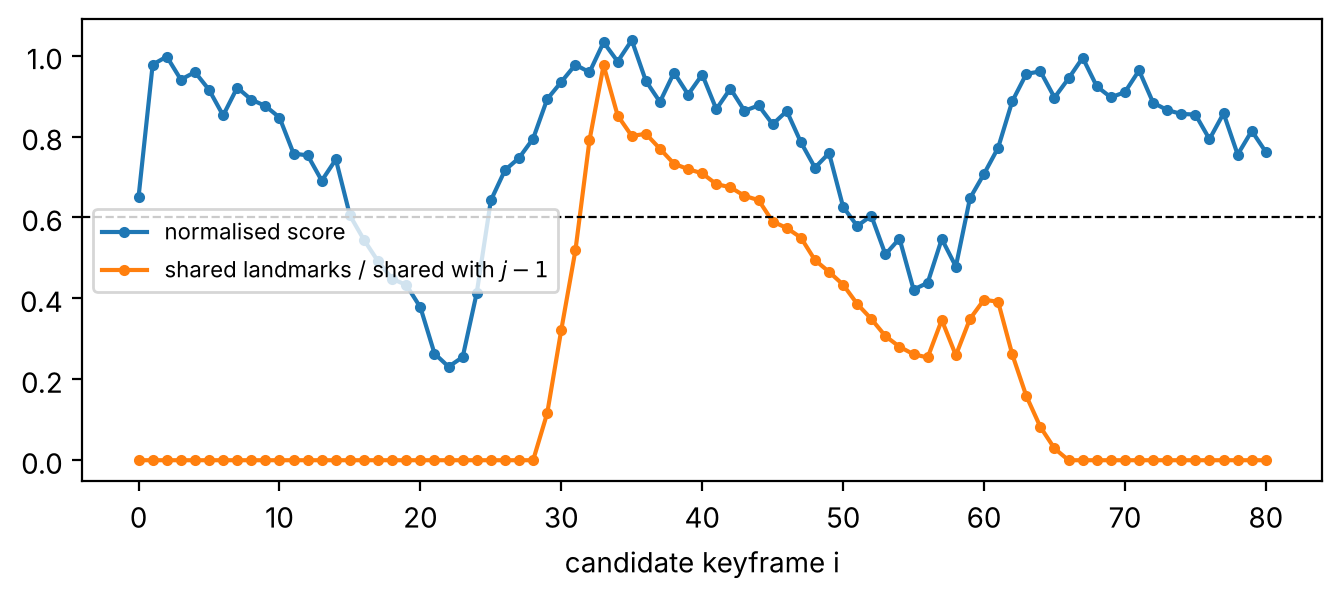

In [5]:
j = 100
c = det.candidates(j)
i_s = np.array([x.i for x in c]); ns = np.array([x.normalised for x in c])
o = np.argsort(i_s)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(i_s[o], ns[o], ".-", label="normalised score")
ax.plot(i_s[o], shared[i_s[o], j] / shared[j - 1, j], ".-", label="shared landmarks / shared with $j-1$")
ax.axhline(det.min_norm, color="k", ls="--", lw=0.8); ax.set_xlabel("candidate keyframe i"); ax.legend(fontsize=8)
print("best candidates:", [(x.i, round(x.normalised, 2), int(shared[x.i, j])) for x in c[:3]])

## 5. Geometric verification

Five-point RANSAC on the bearings, a loose PnP for a metric start, then a two-keyframe stereo BA; the covariance of
the relative pose comes from that BA.

In [6]:
c = det.verify(det.candidates(j)[0])
T_true = lie.se3_inv(G[c.i]) @ G[c.j]
print(f"loop ({c.i}, {c.j}): {c.inliers} inliers, translation error {100 * np.linalg.norm(c.Z[:3,3] - T_true[:3,3]):.1f} cm")
print("1-sigma (cm, deg):", np.r_[100 * np.sqrt(np.diag(c.cov)[:3]), np.degrees(np.sqrt(np.diag(c.cov)[3:]))])

loop (35, 100): 126 inliers, translation error 20.5 cm
1-sigma (cm, deg): [15.0971  1.4479  3.3002  0.0825  0.6482  0.1804]


## 6. All loops, and the pose graph

A loop is called wrong if its translation is more than 0.5 m off.

In [7]:
def all_loops(det, kfr, G):
    found = [c for j in range(len(G)) if (c := det.detect(j)) is not None]
    err = np.array([np.linalg.norm((lie.se3_inv(G[c.i]) @ G[c.j])[:3, 3] - c.Z[:3, 3]) for c in found])
    return found, err

def pose_graphs(P, G, found):
    edges = pg.odometry_edges(P, SIG_T, SIG_R) + loop.loop_edges(found)
    for name, kern in [("least squares", None), ("Cauchy(1)", robust.Cauchy(1.0))]:
        Q = optim.levenberg_marquardt(pg.PoseGraphProblem(edges, len(P)), P, kernel=kern).x
        print(f"  {name:14s} RMS {100 * rms(Q, G):.1f} cm")

found, err = all_loops(det, kfr, G)
print(f"{len(found)} loops, {(err > 0.5).sum()} wrong, median error {100 * np.median(err):.1f} cm")
pose_graphs(P, G, found)

95 loops, 1 wrong, median error 6.5 cm


  least squares  RMS 3.8 cm


  Cauchy(1)      RMS 4.4 cm


## 7. A strongly aliased fence (Section 10.6)

Five picket prototypes and 2 % personal bits: the ratio test now rejects most fence matches (Exercise 10.2), and some
loops rest on a single tree trunk or the shed. Their matches are all correct, but the pose is not: the error lies along
the rotation-translation valley of Proposition 10.10, heading error times the distance of the object.

In [8]:
world5, S5, kfr5, desc5, P5, G5, _ = garden_keyframes(n_fence=5, personal=0.02)
det5 = loop.LoopDetector(voc, S5.stereo, rng=np.random.default_rng(0))
for f, ds in zip(kfr5, desc5):
    det5.add(f.z, ds)
found5, err5 = all_loops(det5, kfr5, G5)
print(f"{len(found5)} loops, {(err5 > 0.5).sum()} wrong")
for c, e in zip(found5, err5):
    if e > 0.5:
        T = lie.se3_inv(G5[c.i]) @ G5[c.j]
        dR = np.degrees(lie.so3_log(c.Z[:3, :3] @ T[:3, :3].T))
        dt = c.Z[:3, 3] - T[:3, 3]
        lm = kfr5[c.j].landmark[c.pairs[:, 1]]
        right = np.mean(kfr5[c.i].landmark[c.pairs[:, 0]] == lm)
        kinds = dict(zip(*np.unique(world5.kind[lm], return_counts=True)))
        dist = np.median(np.linalg.norm(world5.points[lm] - G5[c.i][:3, 3], axis=1))
        print(f"  ({c.i:3d},{c.j:3d}) error {e:.2f} m, d_yaw(cam y) {dR[1]:6.1f} deg, d_x {dt[0]:5.2f} m, "
              f"ratio {abs(dt[0] / np.radians(dR[1])):5.1f} m, object at {dist:4.1f} m, correct matches {100*right:.0f} %, "
              f"{ {str(k): int(v) for k, v in kinds.items()} }")
pose_graphs(P5, G5, found5)

86 loops, 13 wrong
  (  3, 67) error 0.74 m, d_yaw(cam y)    2.9 deg, d_x -0.70 m, ratio  14.0 m, object at 13.5 m, correct matches 100 %, {'fence': 1, 'shed': 29, 'tree': 84}
  (  1, 69) error 2.55 m, d_yaw(cam y)  -11.3 deg, d_x  2.17 m, ratio  11.0 m, object at 14.5 m, correct matches 100 %, {'shed': 10, 'tree': 73}
  (  1, 71) error 2.08 m, d_yaw(cam y)   -9.9 deg, d_x  1.78 m, ratio  10.3 m, object at 14.4 m, correct matches 100 %, {'fence': 3, 'shed': 19, 'tree': 72}
  ( 36,101) error 0.73 m, d_yaw(cam y)    3.4 deg, d_x -0.71 m, ratio  12.1 m, object at 12.9 m, correct matches 100 %, {'fence': 1, 'tree': 82}
  ( 36,102) error 0.95 m, d_yaw(cam y)    4.3 deg, d_x -0.95 m, ratio  12.6 m, object at 13.0 m, correct matches 100 %, {'fence': 4, 'house': 1, 'tree': 70}
  ( 37,104) error 0.68 m, d_yaw(cam y)    3.3 deg, d_x -0.67 m, ratio  11.6 m, object at 12.5 m, correct matches 100 %, {'fence': 1, 'tree': 71}
  ( 39,105) error 2.33 m, d_yaw(cam y)  -12.5 deg, d_x  2.25 m, ratio  10.3

  least squares  RMS 99.8 cm


  Cauchy(1)      RMS 5.3 cm


## Exercises

1. Remove the aliasing (`n_fence=10_000`) and count the wrong loops again.
2. In the aliased garden, raise `min_inliers` to 100. How many correct loops are lost, how many wrong ones survive?
3. Apply the temporal consistency check of Section 10.6 to `found5`. Why does it keep the wrong loops?
4. Gate the loops against the VO: reject a loop whose translation differs from that of $P_i^{-1}P_j$ by more than
   1 m. Which wrong loops survive, and what does the pose graph give?